# ContextNet + MultiNicheNet Workflow

This tutorial demonstrates how to visualize **multi-condition** cell-cell communication data from MultiNicheNet using ccflowR Sankey diagrams.

### What You'll Learn

1. Load MultiNicheNet output with group information
2. Define cell type and group colors
3. Create group-colored Sankey diagrams
4. Compare individual conditions side-by-side
5. Customize and filter for publication figures
6. Export figures

For detailed parameter reference (alpha, labels, fonts, layout, interactive filters, export), see the **Parameter Reference Guide**.

### When to Use MultiNicheNet

| Scenario | Use |
|----------|-----|
| Single condition or timepoint | **NicheNet** |
| Comparing Control vs Treatment | **MultiNicheNet** |
| Multiple disease states | **MultiNicheNet** |
| Developmental stages | **MultiNicheNet** |
| Spatial zones | **MultiNicheNet** |

MultiNicheNet extends NicheNet by adding **differential analysis** between conditions, providing per-condition prioritization scores, log fold-change values, and group-stratified communication networks.

## Data Requirements

### Required Columns
| Column | Type | Description |
|--------|------|-------------|
| `sender` | character | Sending cell type |
| `receiver` | character | Receiving cell type |
| `ligand` | character | Ligand gene symbol |
| `receptor` | character | Receptor gene symbol (optional -- omit with `receptor_col = NULL` for 3-layer plots) |
| `group` | character | Condition label (e.g., "Control", "Treatment") |

ContextNet's `prepare_for_ccflowr()` produces all required columns including expression weights that enable edge thickness to reflect biological signal strength.

### Loading Your Own Data

    # Load your MultiNicheNet output file
    data <- read_multinichenet("path/to/multinichenet_output.csv")
    table(data$group)


In [1]:
library(ccflowR)

# Static display helper (renders PNG for GitHub compatibility)
# Re-run notebook locally for interactive plots
show <- function(p, width = 600, height = 900) {
  tmpfile <- tempfile(fileext = ".png")
  sankey_save(p, tmpfile, width = width, height = height)
  IRdisplay::display_png(file = tmpfile)
  invisible(p)
}

ccflowR v0.1.0 - Cell-Cell Communication Flow Visualization



## Step 1: Load Data

In [2]:
# Use example data for demonstration
ex <- example_multinichenet()
data <- ex$data

# Inspect the data structure
head(data)

# View the groups
table(data$group)

,sender,receiver,ligand,receptor,group,prioritization_score,scaled_lfc_ligand,scaled_lfc_receptor,activity
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Macrophage,T_cell,TGFB1,TGFBR1,Control,0.45,0.40,0.50,0.45
2,Macrophage,Fibroblast,TNF,TNFRSF1A,Control,0.40,0.35,0.45,0.40
3,T_cell,Macrophage,IFNG,IFNGR1,Control,0.50,0.45,0.55,0.50
4,Fibroblast,Endothelial,VEGFA,KDR,Control,0.42,0.38,0.48,0.42
5,T_cell,B_cell,IL2,IL2RA,Control,0.38,0.32,0.42,0.38
6,Endothelial,Fibroblast,PDGFB,PDGFRB,Control,0.35,0.30,0.40,0.35



  Control   Disease Treatment 
        6        12         9 

In [3]:
# Get a summary of the communication data
summarize_data(data)

$n_interactions
[1] 27

$n_senders
[1] 4

$n_receivers
[1] 5

$n_ligands
[1] 8

$n_receptors
[1] 8

$senders
[1] "Macrophage"  "T_cell"      "Fibroblast"  "Endothelial"

$receivers
[1] "T_cell"      "Fibroblast"  "Macrophage"  "Endothelial" "B_cell"     

$ligands
[1] "TGFB1" "TNF"   "IFNG"  "VEGFA" "IL2"   "PDGFB" "IL6"   "CCL2" 

$receptors
[1] "TGFBR1"   "TNFRSF1A" "IFNGR1"   "KDR"      "IL2RA"    "PDGFRB"   "IL6R"    
[8] "CCR2"

You should see 27 interactions across 3 conditions with different network densities: Control has 6 core interactions, Treatment has 9 (adding immune-activation pathways like TGFB1 from Fibroblast and IL6 from Macrophage), and Disease has 12 (adding inflammatory pathways like CCL2 and expanded IFNG/IL6 signaling to B_cell). This mirrors real biology where disease conditions activate additional signaling. The data includes `prioritization_score`, `scaled_lfc_ligand`, and `scaled_lfc_receptor` columns, which enable flow-conserving mode with expression-weighted edge thickness.

## Step 2: Define Colors

**Why two color sets?** MultiNicheNet analysis requires two separate color mappings. Cell type colors identify senders and receivers. Group colors map to experimental conditions so flows can be colored by condition, making it possible to see at a glance which pathways are active in which condition.

In [4]:
# Cell type colors (from example data)
celltype_colors <- ex$colors
print(celltype_colors)

# Group/condition colors (from example data)
group_colors <- ex$group_colors
print(group_colors)

# Verify all groups have colors
groups_in_data <- unique(data$group)
missing <- setdiff(groups_in_data, names(group_colors))
if (length(missing) > 0) {
  cat("Warning: No colors defined for:", paste(missing, collapse = ", "), "\n")
} else {
  cat("All groups have colors assigned\n")
}

 Macrophage      T_cell  Fibroblast Endothelial      B_cell 
  "#E41A1C"   "#377EB8"   "#4DAF4A"   "#984EA3"   "#FF7F00" 


  Control Treatment   Disease 
"#66C2A5" "#FC8D62" "#8DA0CB" 


All groups have colors assigned


## Step 3: Create a Group-Colored Sankey

**Why color by group?** This is the defining feature of MultiNicheNet visualization. Coloring flows by condition lets you see which signaling pathways are shared across conditions and which are condition-specific.

Two functions work together: `sankey_colors(by = "condition")` tells ccflowR to color flows by condition, and `sankey_group_colors()` provides the color mapping.

Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948a7a5bfdd4.png



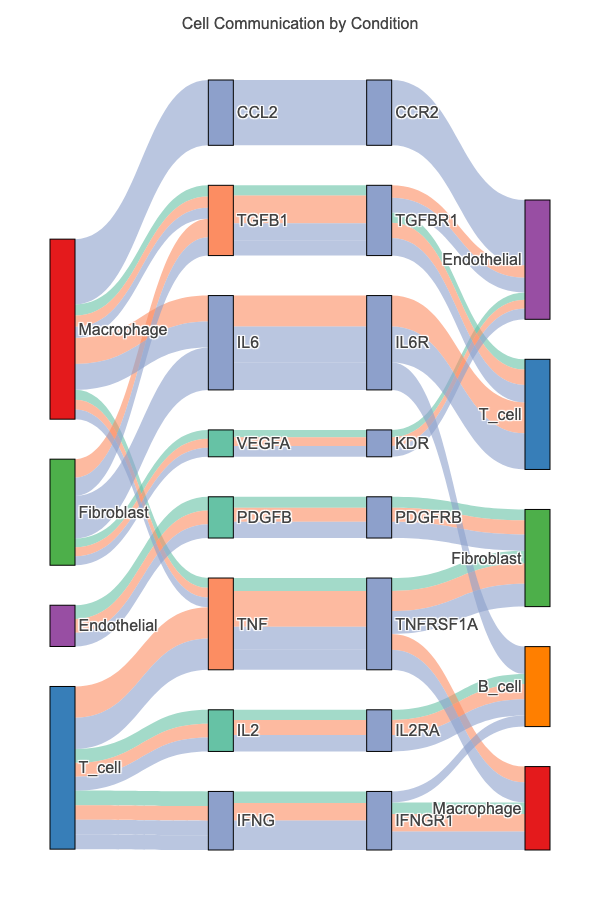

In [5]:
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_alpha(0.6) +
  sankey_title("Cell Communication by Condition")
show(p)

**Reading the plot:**
- Each flow is colored by its experimental condition
- Where flows for the same interaction overlap, you can see which conditions share that pathway
- Flow thickness reflects the prioritization score for each condition — a thicker Treatment flow means that interaction is more active in Treatment
- Ligand-receptor pairs present in all three conditions appear as stacked colored flows at the same position

## Step 4: Compare Individual Conditions

The combined group-colored plot shows all conditions at once but can become dense. Per-condition plots provide cleaner views for direct side-by-side comparison. Use the same `sankey_order()` across all panels to keep node positions consistent.

Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948a374f62ea.png



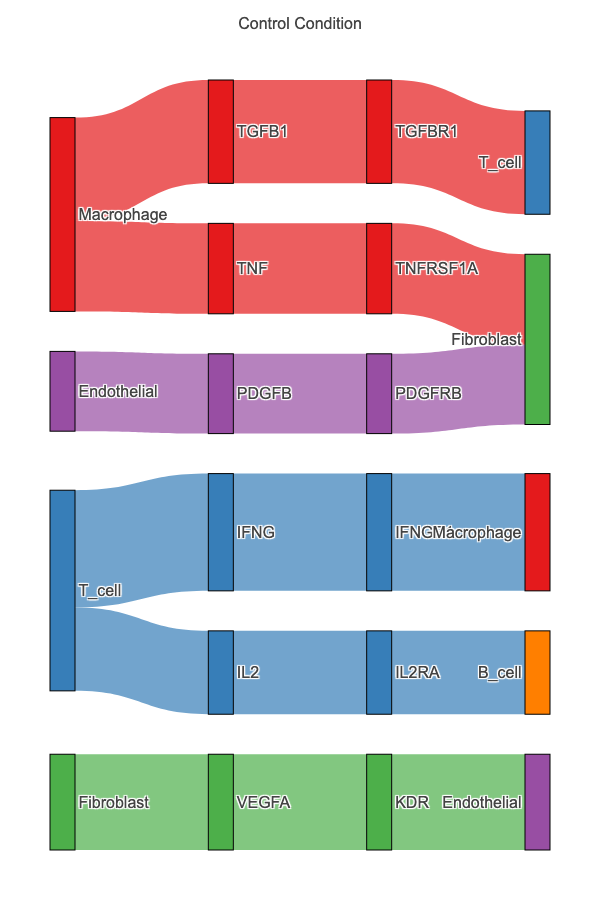

In [6]:
# Filter to Control only
control_data <- data[data$group == "Control", ]

p <- sankey_plot(control_data, celltype_colors) +
  sankey_colors(by = "sender") +
  sankey_alpha(0.7) +
  sankey_title("Control Condition")
show(p)

Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948aa472910.png



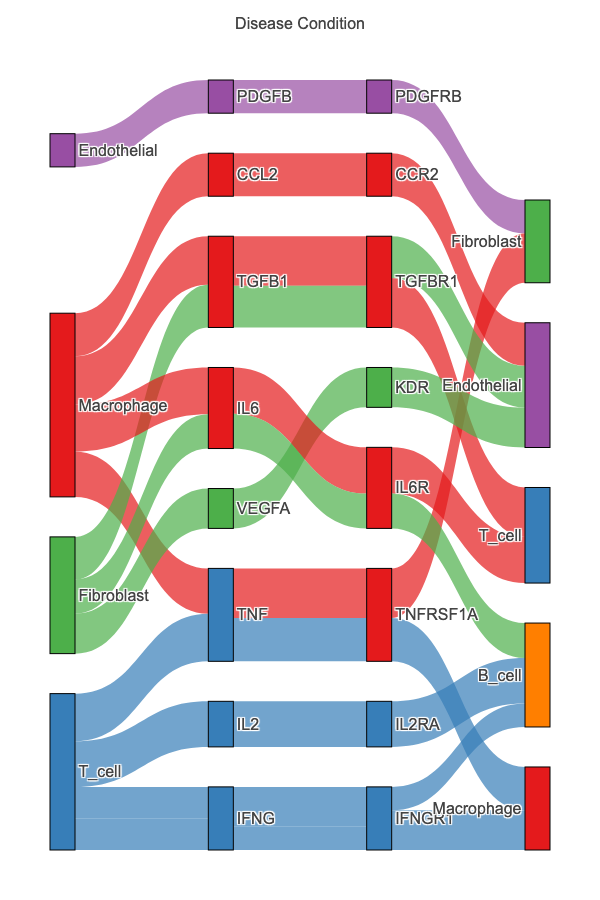

In [7]:
# Filter to Disease only
disease_data <- data[data$group == "Disease", ]

p <- sankey_plot(disease_data, celltype_colors) +
  sankey_colors(by = "sender") +
  sankey_alpha(0.7) +
  sankey_title("Disease Condition")
show(p)

Compare the two plots: Control has only 6 interactions, while Disease adds inflammatory pathways (CCL2, expanded IFNG/IL6 signaling to B_cell). Macrophage sends 2 signals in Control but 4 in Disease, and shared pathways like TGFB1 show progressively stronger signals.

## Step 5: Customize Your Figure

ccflowR customizations work the same way with multi-condition data. See the **Parameter Reference Guide** for all options.

**New features:**
- `sankey_colors(by = "steelblue")` -- use any color string for monochrome flows
- `sankey_nodes(arrangement = "snap")` -- enable interactive node dragging
- `sankey_plot(..., receptor_col = NULL)` -- omit receptor layer for 3-layer diagrams

Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948a380715ea.png



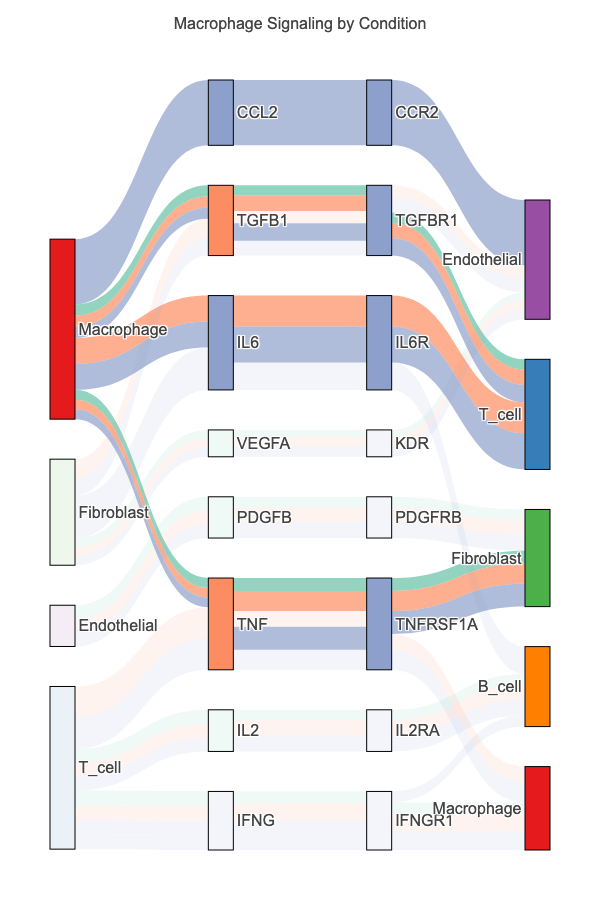

In [8]:
# Highlight Macrophage signaling across all conditions
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_highlight(senders = "Macrophage", dim_alpha = 0.1) +
  sankey_alpha(0.7) +
  sankey_title("Macrophage Signaling by Condition")
show(p)

### Custom Node Ordering

By default, nodes are ordered using a barycenter heuristic that minimizes link crossings. Keep node positions consistent across all panels for direct visual comparison by specifying a custom order.

Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948a7be6ed81.png



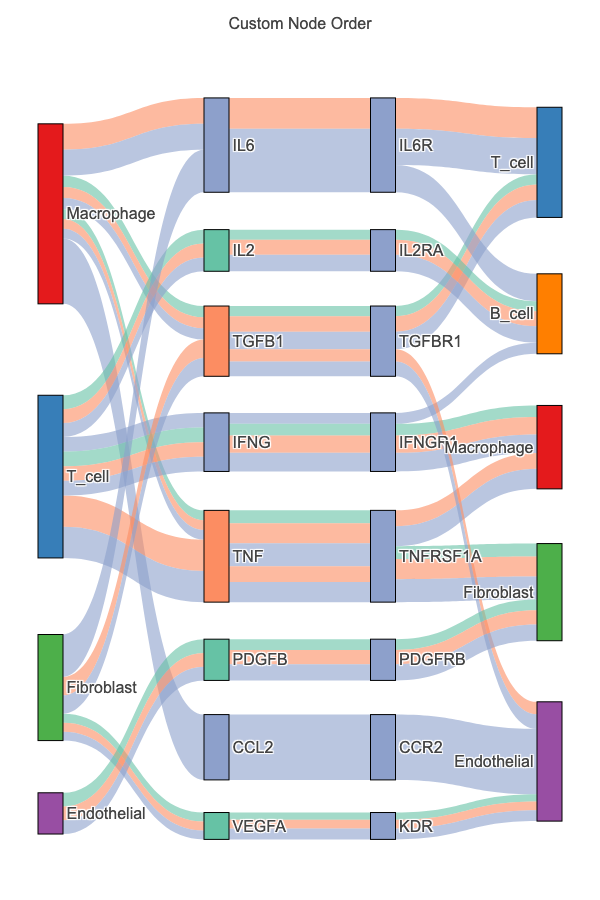

In [9]:
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_order(
    senders = c("Macrophage", "T_cell", "B_cell", "Fibroblast", "Endothelial"),
    receivers = c("T_cell", "B_cell", "Macrophage", "Fibroblast", "Endothelial")
  ) +
  sankey_alpha(0.6) +
  sankey_title("Custom Node Order")
show(p)

## Step 6: Filter Top Interactions

MultiNicheNet data often contains many interactions. Use `filter_top_pathways()` with `per_group = TRUE` to get the top N from each condition, ensuring balanced representation across groups.

Selected top 5 pathways by activity



Interactions per group after filtering:



  Control   Disease Treatment 
        5         5         5 


Mapped MultiNicheNet columns to standard names



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmpDrlZRc/file948a7abfa0b7.png



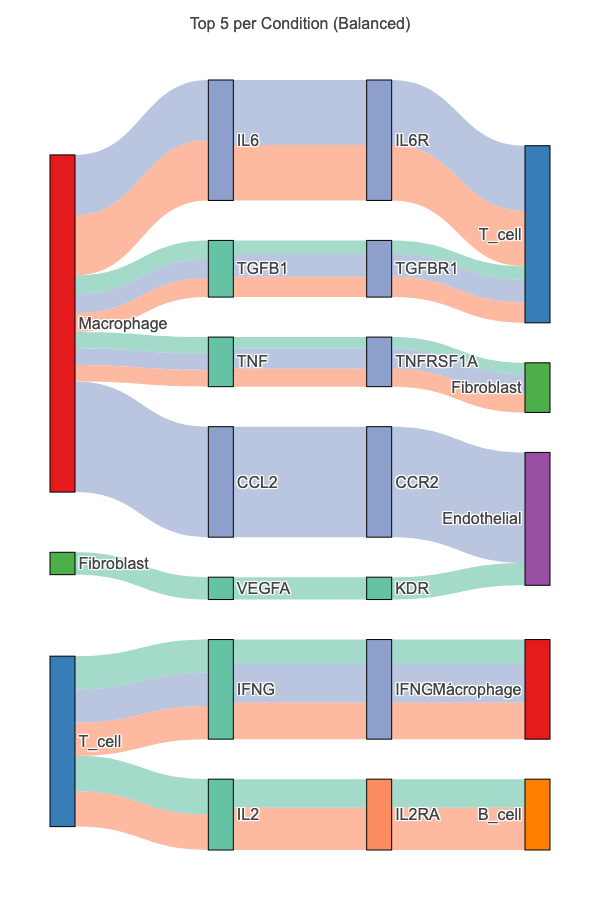

In [10]:
# Filter to top 5 per condition — ensures balanced representation
top_per_group <- filter_top_pathways(data, n = 5, per_group = TRUE, group_col = "group")
cat("Interactions per group after filtering:\n")
print(table(top_per_group$group))

p <- sankey_plot(top_per_group, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_alpha(0.6) +
  sankey_title("Top 5 per Condition (Balanced)")
show(p)

## Step 7: Export

Save your figure as HTML (interactive) or static formats (PNG, PDF, SVG). See the **Parameter Reference Guide** for all export options and format details.

In [11]:
# Build a publication-ready figure
p <- sankey_plot(data, celltype_colors, group_col = "group") +
  sankey_colors(by = "condition") +
  sankey_group_colors(group_colors) +
  sankey_highlight(senders = "Macrophage") +
  sankey_alpha(0.6) +
  sankey_title("Macrophage Signaling by Condition")

# Save as interactive HTML (always works, no dependencies)
sankey_save(p, "example_output.html")
cat("Saved HTML\n")

# Save as static PNG (requires kaleido or webshot2)
# sankey_save(p, "example_output.png", width = 700, height = 900)

# Clean up
if (file.exists("example_output.html")) file.remove("example_output.html")

Mapped MultiNicheNet columns to standard names



Warning message in dir.create(outputDir, recursive = TRUE):
“'example_output_files' already exists”


Warning message in dir.create(target_dir):
“'example_output_files/jquery-3.5.1' already exists”


Warning message in dir.create(target_dir):
“'example_output_files/crosstalk-1.2.2' already exists”


Saved interactive HTML to: example_output.html



Saved HTML


## Complete Workflow

    library(ccflowR)

    # 1. Load your MultiNicheNet output
    data <- read_multinichenet("path/to/multinichenet_output.csv")
    print(table(data$group))

    # 2. Define colors
    celltype_colors <- c(
      "B Cell" = "#17BECF", "T Cell" = "#006837",
      "Myeloid" = "#FF7F0E", "Fibroblast" = "#9C46D3",
      "Epithelial" = "#1F77B4", "Endothelial" = "#E89FBD"
    )
    group_colors <- c(
      "Control" = "#ADD8E6", "Treatment" = "#F08080", "Disease" = "#90EE90"
    )

    # 3. Create comparison figure
    p <- sankey_plot(data, celltype_colors, group_col = "group") +
      sankey_colors(by = "condition") +
      sankey_group_colors(group_colors) +
      sankey_alpha(0.6) +
      sankey_title("Condition Comparison")

    # 4. Save (see Parameter Reference Guide for all export options)
    sankey_save(p, "Figure2_comparison.html")
    sankey_save(p, "Figure2_comparison.png", width = 700, height = 900)

## Troubleshooting

| Issue | Solution |
|-------|----------|
| "group column not found" | Ensure your data has a `group` column, or specify the correct name with `group_col` |
| Colors don't match conditions | Check that `sankey_group_colors()` names match unique values in the group column |
| Too many flows | Use `filter_top_pathways(data, n = 10, per_group = TRUE)` to reduce density |
| Nodes in wrong order | Default uses barycenter ordering. Use `sankey_order()` to set explicit positions |
| Want receptor-free view | Use `sankey_plot(..., receptor_col = NULL)` for a 3-layer Sender -> Ligand -> Receiver diagram |

## Next Steps
- **Single condition analysis**: See the [NicheNet tutorial](tutorial-contextnet-nichenet.ipynb) for detailed single-condition workflows
- **Parameter reference**: See the [Parameter Guide](tutorial-parameter-guide.ipynb) for all customization options, including 3-layer mode (`receptor_col`), fixed flow colors, and node arrangement modes
- **Export options**: `sankey_save()` supports HTML, PNG, PDF, and SVG formats